# 06 — Performance and validation

Numbers come from `reports/bench.json` on the machine that ran the release binary. They are not a hardware-independent throughput.

Checkpoint time is the final shallow book, not the event log. The correctness check for checkpoints is the OCaml test that a restored suffix matches a full replay hash, not this timer.

Measured on the machine that ran queuelab benchmark. Do not cite as a hardware-independent throughput.
Linux 6.12.8+
Intel(R) Xeon(R) Platinum 8481C CPU @ 2.70GHz
MemTotal:        4024496 kB
ocaml 5.3.0 profile release
dataset events 5357 median replay s 0.0032639503479003906
synthetic events 266598 median replay s 0.23463106155395508
events/s 1136243.4207744226
checkpoint median s 4.0531158447265625e-06


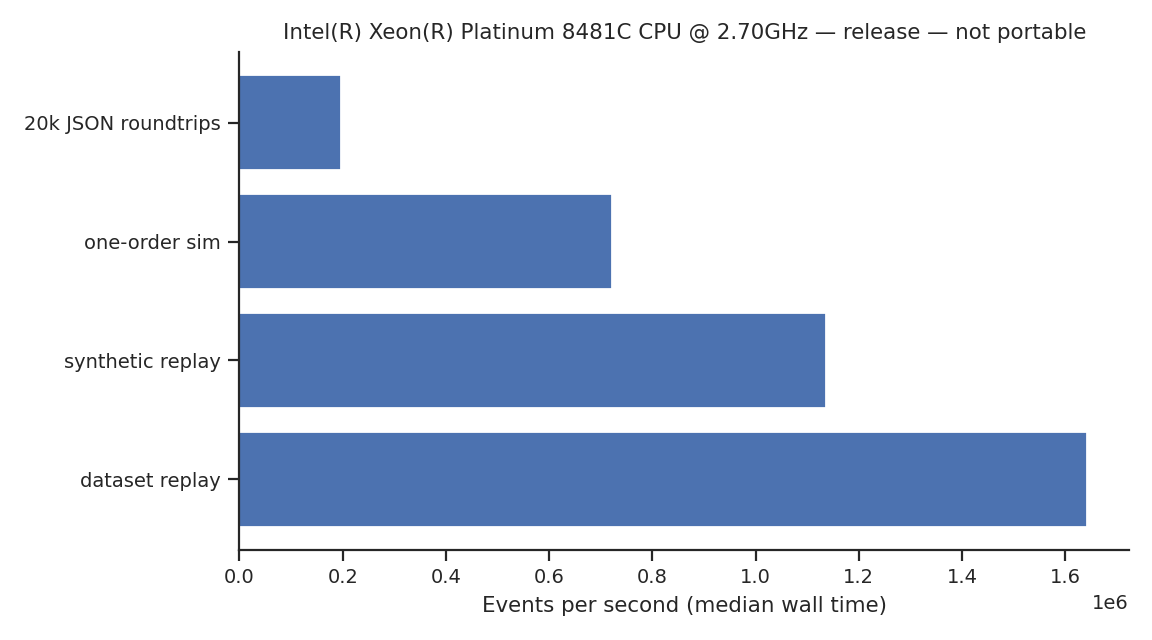

replay hash fd11f4eff6e97d8eb8d488bbf7d0d52c quality ok True


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "scripts" / "analysis.py").is_file():
    raise SystemExit("run this notebook from the repository root")
sys.path.insert(0, str(ROOT / "scripts"))
import analysis
from IPython.display import Image, display

def show(name):
    display(Image(filename=str(analysis.FIG / f"{name}.png")))

bench = analysis.benchmark()
print(bench["note"])
print(bench["uname"])
print(bench["cpu"])
print(bench["meminfo"])
print("ocaml", bench["ocaml"], "profile", bench["profile"])
print("dataset events", bench["dataset_events"], "median replay s", bench["dataset_replay"]["median_s"])
print("synthetic events", bench["synthetic_events"], "median replay s", bench["synthetic_replay"]["median_s"])
print("events/s", bench["events_per_second_synthetic_median"])
print("checkpoint median s", bench["checkpoint_roundtrip_synthetic"]["median_s"])
analysis.plot_benchmark(bench, analysis.FIG)
show("benchmark_rates")
q = analysis.quality()
print("replay hash", q["book_hash"], "quality ok", q["ok"])


Tests that must already be green before trusting this notebook: `dune runtest`. That run covers sync, duplicate, gap, deterministic replay, checkpoint resume, the conservative/optimistic divergence, no double-count, cancel/fill race, ledger identity and a QCheck book update.